<h1 align="center">CoNECTOME Hackathon</h1>  
<h1 align="center">Allen Institute/Neural Dynamics</h1>  
<h4 align="center"> May 20, 2026 </h4>   
<h4 align="center"> Dynamic Routing</h4> 
    

**Goal:** This tutorial will cover data access, details of the experiment, exploration and scientific analysis.

  We will:
  1. Find & load data packaged as NWB files
  2. Explain the design of the Dynamic Routing task
  3. Calculate behavioral performance metrics
  4. Summarize the brain areas recorded
  5. Explore data around stimulus onset: neural activity, running speed, face motion

# TODO before the hackathon
- [x] Remove hdf5 files
- [ ] Update NWB paths in .json to latest version
- [ ] Add vl-convert-python to env

In [1]:
%%javascript
requirejs.undef('vega-embed');
requirejs.undef('vega');
requirejs.undef('vega-lite');

<IPython.core.display.Javascript object>

In [2]:
%matplotlib inline
%load_ext autoreload
%autoreload 2 

In [3]:
import json
import pathlib
import warnings

import altair as alt
import lazynwb
from lazynwb import config
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

alt.renderers.enable("png", ppi=150)
warnings.filterwarnings("ignore", module="hdmf_zarr")

config.anon = True
pl.Config.set_tbl_rows(12)
pl.Config.set_tbl_width_chars(-1)
pl.Config.set_fmt_str_lengths(100)


polars.config.Config

---

## File inventory
Includes metadata (from .json files in each session data asset)

In [4]:
assets_path = pathlib.Path("assets_zarr.json")
if not assets_path.exists():
    assets_path = pathlib.Path("code/assets_zarr.json")

assets = pl.read_json(assets_path)
assets


id,mount,nwb_path
str,str,str
"""989bb861-2d1f-4fc9-9944-21b0d00d3e8c""","""ecephys_664851_2023-11-15_12-38-21_nwb_2026-05-18_21-58-33""","""s3://aind-open-data/ecephys_664851_2023-11-15_12-38-21_nwb_2026-05-18_21-58-33/664851_2023-11-15.nwb…"
"""5c06cd1d-a50a-4eab-94bf-f4d7bab7126e""","""ecephys_759434_2025-02-04_12-27-22_nwb_2026-05-18_21-56-27""","""s3://aind-open-data/ecephys_759434_2025-02-04_12-27-22_nwb_2026-05-18_21-56-27/759434_2025-02-04.nwb…"
"""dea47e13-3a87-44dd-9517-ed2530d0771b""","""ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14""","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…"
"""5d863728-b41a-4715-a631-640540132860""","""ecephys_668755_2023-08-31_12-33-31_nwb_2026-05-18_21-59-03""","""s3://aind-open-data/ecephys_668755_2023-08-31_12-33-31_nwb_2026-05-18_21-59-03/668755_2023-08-31.nwb…"
"""191ecd4e-43db-450a-9abc-bebbb3fd4ec0""","""ecephys_713655_2024-08-09_10-41-47_nwb_2026-05-18_21-59-59""","""s3://aind-open-data/ecephys_713655_2024-08-09_10-41-47_nwb_2026-05-18_21-59-59/713655_2024-08-09.nwb…"


### Opening a file
<img src="images/nwb-file.png" width="300">

Read one NWB-Zarr file using `lazynwb`:


In [5]:
SESSION_ID = "742903_2024-10-22"

selected_path = assets.filter(
    pl.col("nwb_path").str.contains(SESSION_ID)
)["nwb_path"][0]

print(selected_path)


s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb.zarr


`lazynwb` lets us read only the table or time series we need, instead of opening a full `NWBFile` object.

Listing internal paths is a quick way to see what is inside the file:


In [6]:
internal_paths = lazynwb.get_internal_paths(selected_path)
internal_paths[:20]


['/acquisition/frametimes_eye_camera',
 '/acquisition/frametimes_front_camera',
 '/acquisition/frametimes_side_camera',
 '/acquisition/manipulator_positions',
 '/intervals/aud_rf_mapping_trials',
 '/intervals/epochs',
 '/intervals/optotagging_trials',
 '/intervals/performance',
 '/intervals/trials',
 '/intervals/vis_rf_mapping_trials',
 '/processing/behavior/dlc_eye_camera',
 '/processing/behavior/eye_tracking',
 '/processing/behavior/facemap_front_camera',
 '/processing/behavior/facemap_side_camera',
 '/processing/behavior/licks',
 '/processing/behavior/lp_front_camera',
 '/processing/behavior/lp_side_camera',
 '/processing/behavior/quiescent_interval_violations',
 '/processing/behavior/rewards',
 '/processing/behavior/running_speed']

*[while waiting]* open `/data` in the file explorer and browse one of the `.zarr` NWB folders if the data are mounted locally.

> **Note:** For remote S3 paths, the first access can take a little longer while metadata are discovered and cached.


## Epochs within a session

Tables are read by their internal path. "epochs" are stored as a table of intervals (i.e. each row has a `start_time` and a `stop_time`):


In [7]:
epochs = lazynwb.scan_nwb(selected_path, "/intervals/epochs").collect()
epochs


id,interval_names,notes,script_name,start_time,stop_time,tags,_nwb_path,_table_path,_table_index
i64,list[str],str,str,f64,f64,list[str],str,str,u32
0,"[""vis_rf_mapping_trials"", ""aud_rf_mapping_trials""]","""""","""RFMapping""",44.79145,915.504865,"[""mapping""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",0
1,"[""optotagging_trials""]","""""","""OptoTagging""",925.76399,1276.57267,"[""optotagging""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",1
2,[],"""""","""Spontaneous""",1286.79894,1889.936475,"[""spontaneous""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",2
3,[],"""""","""SpontaneousRewards""",1900.7289,2503.80082,"[""rewards"", ""spontaneous""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",3
4,"[""trials"", ""performance""]","""""","""DynamicRouting1""",2514.35961,6155.32561,"[""task"", ""rewards""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",4
5,[],"""""","""SpontaneousRewards""",6166.13478,6769.25658,"[""rewards"", ""spontaneous""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",5
6,[],"""""","""Spontaneous""",6779.73208,7382.853835,"[""spontaneous""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",6
7,"[""optotagging_trials""]","""""","""OptoTagging""",7393.26257,7741.75442,"[""optotagging""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",7


Get a table as a polars dataframe:


In [8]:
epochs


id,interval_names,notes,script_name,start_time,stop_time,tags,_nwb_path,_table_path,_table_index
i64,list[str],str,str,f64,f64,list[str],str,str,u32
0,"[""vis_rf_mapping_trials"", ""aud_rf_mapping_trials""]","""""","""RFMapping""",44.79145,915.504865,"[""mapping""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",0
1,"[""optotagging_trials""]","""""","""OptoTagging""",925.76399,1276.57267,"[""optotagging""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",1
2,[],"""""","""Spontaneous""",1286.79894,1889.936475,"[""spontaneous""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",2
3,[],"""""","""SpontaneousRewards""",1900.7289,2503.80082,"[""rewards"", ""spontaneous""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",3
4,"[""trials"", ""performance""]","""""","""DynamicRouting1""",2514.35961,6155.32561,"[""task"", ""rewards""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",4
5,[],"""""","""SpontaneousRewards""",6166.13478,6769.25658,"[""rewards"", ""spontaneous""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",5
6,[],"""""","""Spontaneous""",6779.73208,7382.853835,"[""spontaneous""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",6
7,"[""optotagging_trials""]","""""","""OptoTagging""",7393.26257,7741.75442,"[""optotagging""]","""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/epochs""",7


Visualized, we can see that each session contains multiple epochs:
- `DynamicRouting1` is the task, which lasts about an hour
- some epochs are repeated after the task

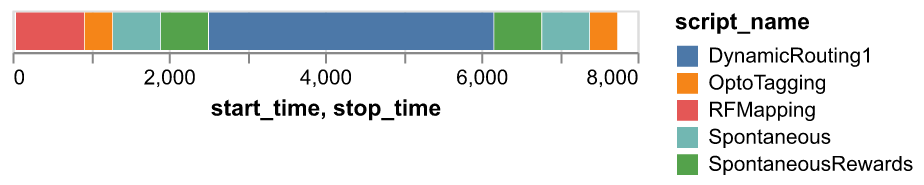

In [9]:
(
    alt.Chart(data=epochs)
    .mark_bar()
    .encode(
        x="start_time",
        x2="stop_time",
        color="script_name",
    )
)


Each epoch may be sub-divided into smaller intervals, e.g. trials or blocks of trials.

The epochs table gives us the name of the other intervals tables that correspond to each epoch.

In [10]:
epochs.select("script_name", "interval_names")


script_name,interval_names
str,list[str]
"""RFMapping""","[""vis_rf_mapping_trials"", ""aud_rf_mapping_trials""]"
"""OptoTagging""","[""optotagging_trials""]"
"""Spontaneous""",[]
"""SpontaneousRewards""",[]
"""DynamicRouting1""","[""trials"", ""performance""]"
"""SpontaneousRewards""",[]
"""Spontaneous""",[]
"""OptoTagging""","[""optotagging_trials""]"


---
# `DynamicRouting1` task trials



## `trials` table

- accessible at the internal path `/intervals/trials`

- **each row is one trial in the task**

- column types:
    - events (`*_time` suffix) 
        - `float`, seconds relative to start of session
    - boolean metadata (`is_*` prefix)
        - for easy filtering of rows
    - other metadata (`stim_name`, `rewarded_modality`, `block_index`) 
        - `int`, `str`
- column descriptions packaged in the NWB file:

    | column | description |
    |--------|-------------|
    | `stim_name` | the stimulus presented; corresponds to a unique stimulus definition, randomized over trials |
    | `rewarded_modality` | indicates the name of the rewarded modality in each block; not an exact correspondence with the values in `stim_name` |
    | `stim_start_time` | onset of visual or auditory stimulus |
    | `is_response` | the subject licked one or more times during the response window |
    | `reward_time` | delivery time of water reward, for contingent and non-contingent rewards |
    | ... | .. |


In [11]:
trials = lazynwb.scan_nwb(selected_path, "/intervals/trials").collect()
trials


block_index,grating_phase,id,is_aud_nontarget,is_aud_rewarded,is_aud_stim,is_aud_target,is_block_switch,is_catch,is_contingent_reward,is_correct,is_correct_reject,is_false_alarm,is_go,is_hit,is_incorrect,is_instruction,is_miss,is_nogo,is_noncontingent_reward,is_nontarget,is_opto,is_repeat,is_response,is_reward_scheduled,is_rewarded,is_target,is_task_control_correct,is_vis_nontarget,is_vis_rewarded,is_vis_stim,is_vis_target,post_response_window_start_time,post_response_window_stop_time,quiescent_start_time,quiescent_stop_time,repeat_index,response_time,response_window_start_time,response_window_stop_time,reward_time,rewarded_modality,start_time,stim_name,stim_start_time,stim_stop_time,stop_time,task_control_response_time,trial_index,trial_index_in_block,_nwb_path,_table_path,_table_index
i64,f64,i64,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,f64,f64,f64,f64,i64,f64,str,str,u32
0,NaN,0,false,true,true,true,false,false,true,true,false,false,true,true,false,true,false,false,false,false,false,false,true,true,true,true,false,false,false,false,false,2522.33292,2525.33544,2519.80321,2521.27107,0.0,2521.82993,2521.38786,2522.3053,2521.85489,"""aud""",2519.80321,"""aud+""",2521.31188,2521.81188,2525.3078,2521.83822,0,0.0,"""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/trials""",0
0,NaN,1,false,true,true,true,false,false,true,true,false,false,true,true,false,true,false,false,false,false,false,false,true,true,true,true,false,false,false,false,false,2527.97097,2530.97349,2525.44123,2526.90917,0.0,2527.11877,2527.02589,2527.94336,2527.14271,"""aud""",2525.44123,"""aud+""",2526.94985,2527.44985,2530.94584,2527.12598,1,1.0,"""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/trials""",1
0,NaN,2,false,true,true,true,false,false,true,true,false,false,true,true,false,true,false,false,false,false,false,false,true,true,true,true,false,false,false,false,false,2538.79673,2541.79925,2536.26697,2537.73488,0.0,2537.95773,2537.85162,2538.76911,2537.9851,"""aud""",2536.26697,"""aud+""",2537.77573,2538.27573,2541.7716,2537.96839,2,2.0,"""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/trials""",2
0,NaN,3,false,true,true,true,false,false,true,true,false,false,true,true,false,true,false,false,false,false,false,false,true,true,true,true,false,false,false,false,false,2544.80177,2547.804292,2542.27204,2543.73989,0.0,2543.96458,2543.85669,2544.77445,2543.99012,"""aud""",2542.27204,"""aud+""",2543.78094,2544.28094,2547.77662,2543.97345,3,3.0,"""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/trials""",3
0,NaN,4,false,true,true,true,false,false,true,true,false,false,true,true,false,true,false,false,false,false,false,false,true,true,true,true,false,false,false,false,false,2554.4265,2557.42903,2551.89673,2553.36467,0.0,2553.56528,2553.48137,2554.39889,2553.59819,"""aud""",2551.89673,"""aud+""",2553.40561,2553.90561,2557.40138,2553.5815,4,4.0,"""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/trials""",4
0,NaN,5,true,true,true,false,false,false,false,false,false,true,false,false,true,false,false,true,false,true,false,false,true,false,false,false,false,false,false,false,false,2563.08377,2566.08629,2560.55403,2562.02205,0.0,2562.24584,2562.13866,2563.05609,NaN,"""aud""",2560.55403,"""aud-""",2562.06264,2562.56264,2566.0586,2562.25539,5,5.0,"""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/trials""",5
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
5,NaN,532,fals

Let's "discover" the block structure of the task by visualizing how the `rewarded_modality` changes across blocks:

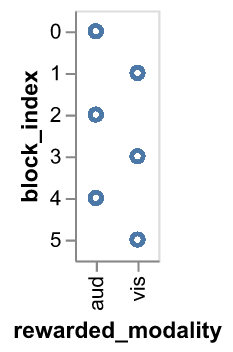

In [12]:
(
    alt.Chart(data=trials)
    .mark_point()
    .encode(
        x="rewarded_modality",
        y="block_index:N",          # :N says this a "nominal" (or categorical) variable, not quantitative
    )
)


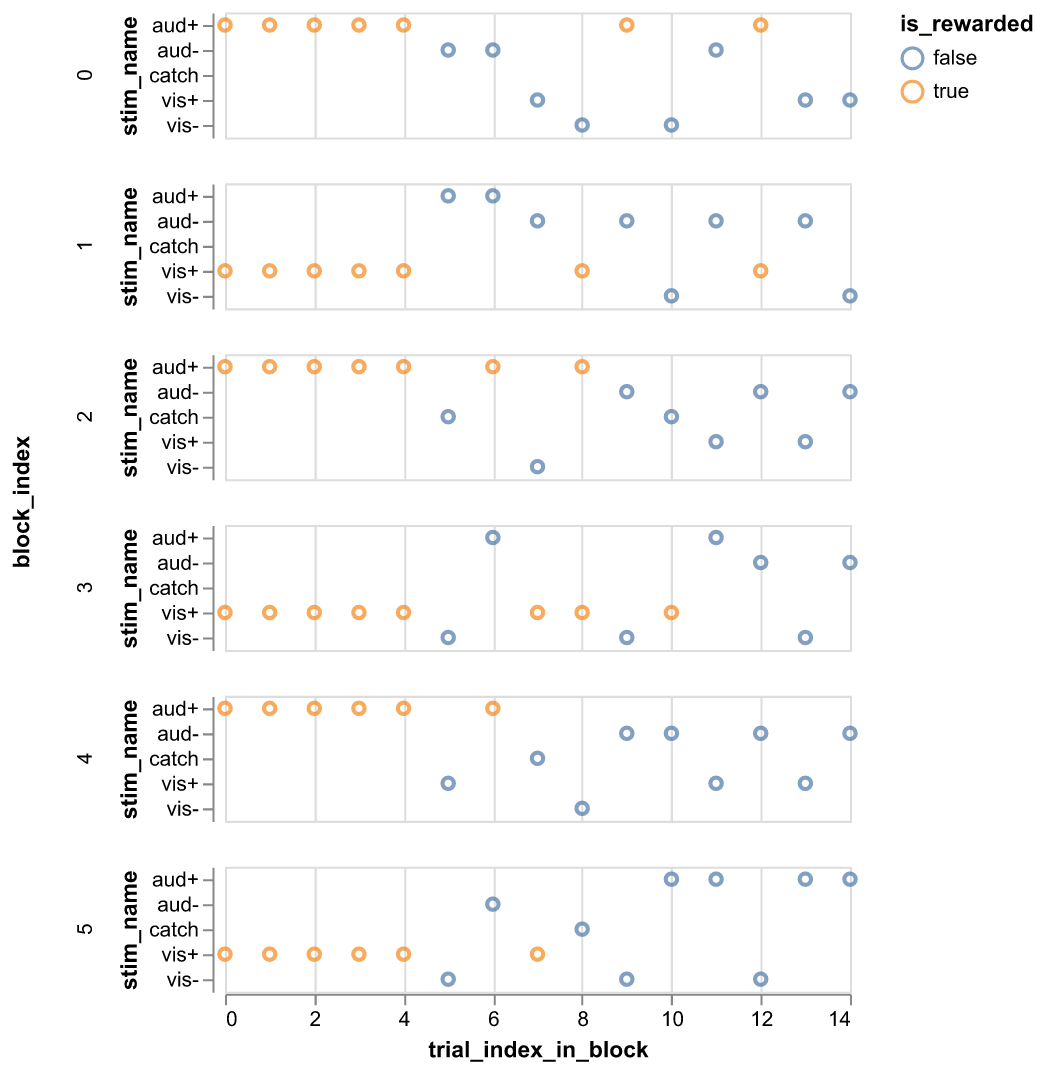

In [13]:
(
    # stimulus identity in the first few trials of each block:
    alt.Chart(data=trials.filter(pl.col("trial_index_in_block") < 15))
    .mark_point()
    .encode(
        x="trial_index_in_block",
        y="stim_name",
        row="block_index",
        color="is_rewarded",
        tooltip=["stim_name", "is_target"],
    )
    .properties(height=60)
)


## Timing within a trial

All times in the NWB file are relative to the start of the session (ie before the first epoch starts).

We can work with times relative to the stimulus onset in each trial by subtracting off `stim_start_time`:

In [14]:
time_cols = [c for c in trials.columns if c.endswith("_time")]

aligned_trials = trials.with_columns(
    (pl.col(c) - pl.col("stim_start_time")).alias(c)
    for c in time_cols
)


<img src="images/trial-timing.png" width="800">

Relevant columns:
- `quiescent_start_time` and `quiescent_stop_time`
- `stim_start_time`
- `response_time` -  when the mouse licked (`NaN` if no lick)

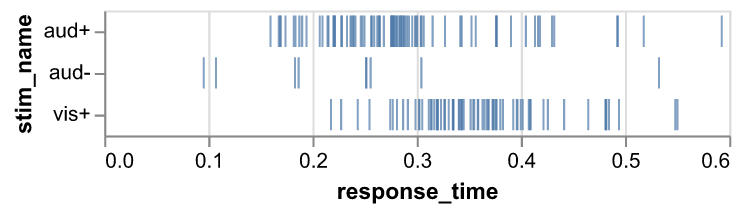

In [15]:
(
    alt.Chart(data=aligned_trials)
    .mark_tick()
    .encode(
        x="response_time",
        y="stim_name",
    )
)


## Behavioral performance

We can aggregate trial outcomes into blockwise performance metrics, e.g. "response rate in each block" using polars `group_by`.

Alternatively, the NWB file contains a pre-computed `performance` table.


In [16]:
performance = lazynwb.scan_nwb(selected_path, "/intervals/performance").collect()
performance


aud_dprime,aud_nontarget_response_rate,aud_target_response_rate,block_index,catch_response_rate,cross_modality_dprime,false_alarm_rate,hit_rate,id,is_first_block_aud,n_contingent_rewards,n_hits,n_responses,n_trials,rewarded_modality,signed_cross_modality_dprime,start_time,stop_time,vis_dprime,vis_nontarget_response_rate,vis_target_response_rate,_nwb_path,_table_path,_table_index
f64,f64,f64,i64,f64,f64,f64,f64,i64,bool,f64,f64,f64,i64,str,f64,f64,f64,f64,f64,f64,str,str,u32
3.022234,0.157895,1.0,0,2.7,3.612305,0.075472,1.0,0,true,23.0,23.0,27.0,86,"""aud""",-3.612305,2519.80321,3117.42034,-0.051774,0.0,0.055556,"""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/performance""",0
0.0,0.0,0.210526,1,3.5,2.555282,0.068966,0.96,1,true,24.0,24.0,28.0,91,"""vis""",2.555282,3117.87068,3727.89821,3.71065,0.0,1.0,"""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/performance""",1
3.370542,0.052632,1.0,2,3.555556,2.086724,0.137931,0.96,2,true,24.0,24.0,32.0,92,"""aud""",-2.086724,3729.78312,4337.809,0.022032,0.0,0.368421,"""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/performance""",2
-0.31511,0.05,0.15,3,9.333333,2.787119,0.065574,0.96,3,true,24.0,24.0,28.0,89,"""vis""",2.787119,4337.94244,4945.08438,3.731438,0.0,1.0,"""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/performance""",3
2.246693,0.2,0.95,4,4.833333,2.686623,0.1,0.92,4,true,23.0,23.0,29.0,91,"""aud""",-2.686623,4945.35125,5550.4581,0.0,0.0,0.1,"""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/performance""",4
0.0,0.0,0.25,5,2.571429,0.779123,0.086207,0.541667,5,true,13.0,13.0,18.0,89,"""vis""",0.779123,5552.00943,6151.41151,2.019139,0.0,0.473684,"""s3://aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb…","""intervals/performance""",5


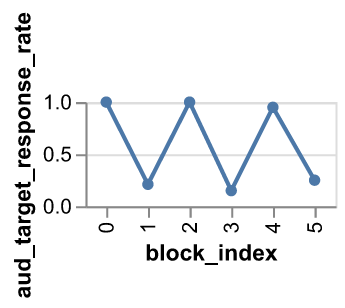

In [17]:
(
    alt.Chart(data=performance)
    .mark_line(point=True)
    .encode(
        x="block_index:N",
        y="aud_target_response_rate",
    )
    .properties(height=50)
)


---
# Neural data

The `units` table contains metadata about each recorded (putative) neuron.

It also contains a list-like `spike_times` column, and the array-like `waveform_mean` and `waveform_sd` columns which can be very large compared to the scalar metadata.

Let's load the units dataframe without the array columns:

In [18]:
unit_cols = [
    "structure",
    "unit_id",
    "location",
    "electrode_group_name",
    "is_qc_pass",
    "activity_drift",
    "firing_rate",
    "num_spikes",
    "ccf_ap",
    "ccf_ml",
    "ccf_dv",
    "decoder_label",
]

units = (
    lazynwb.scan_nwb(selected_path, "/units", exclude_array_columns=True)
    .select(unit_cols)
    .collect()
)
units


structure,unit_id,location,electrode_group_name,is_qc_pass,activity_drift,firing_rate,num_spikes,ccf_ap,ccf_ml,ccf_dv,decoder_label
str,str,str,str,bool,f64,f64,f64,f64,f64,f64,str
"""LSr""","""742903_2024-10-22_A-0""","""LSr""","""probeA""",true,0.040825,4.891656,37776.0,4450.0,4950.0,4400.0,"""sua"""
"""LSr""","""742903_2024-10-22_A-1""","""LSr""","""probeA""",false,0.039527,0.113434,876.0,4450.0,4950.0,4400.0,"""mua"""
"""LSr""","""742903_2024-10-22_A-2""","""LSr""","""probeA""",false,0.228825,5.526551,42679.0,4400.0,4950.0,4400.0,"""mua"""
"""LSr""","""742903_2024-10-22_A-3""","""LSr""","""probeA""",false,0.054993,0.053998,417.0,4400.0,4950.0,4400.0,"""mua"""
"""LSr""","""742903_2024-10-22_A-4""","""LSr""","""probeA""",true,0.095975,0.860339,6644.0,4400.0,4950.0,4400.0,"""sua"""
"""LSr""","""742903_2024-10-22_A-5""","""LSr""","""probeA""",true,0.059574,0.259241,2002.0,4400.0,4950.0,4350.0,"""mua"""
…,…,…,…,…,…,…,…,…,…,…,…
"""ORBm""","""742903_2024-10-22_F-780""","""ORBm5""","""probeF""",false,0.045172,0.067465,521.0,3100.0,5100.0,3350.0,"""sua"""
"""MOs""","""742903_2024-10-22_F-781""","""MOs1""","""probeF""",false,NaN,0.092457,714.0,2600.0,4400.0,1900.0,"""noise"""


In [19]:
units.columns


['structure',
 'unit_id',
 'location',
 'electrode_group_name',
 'is_qc_pass',
 'activity_drift',
 'firing_rate',
 'num_spikes',
 'ccf_ap',
 'ccf_ml',
 'ccf_dv',
 'decoder_label']


## Brain areas recorded

In [20]:
ccf_df = pl.read_csv(
    "https://raw.githubusercontent.com/cortex-lab/allenCCF/refs/heads/master/structure_tree_safe_2017.csv"
).select("name", "acronym")

(
    units.group_by("structure")
    .agg(
        pl.len().alias("n units"),
        pl.col("is_qc_pass").sum().alias("n passing qc"),
    )
    .sort("n units", descending=True)
    .join(ccf_df, left_on="structure", right_on="acronym")
    .sort("structure")
    .select(
        pl.col("name").alias("description"),
        pl.col("structure").alias("structure (acronym)"),
        "n units",
        "n passing qc",
    )
)


description,structure (acronym),n units,n passing qc
str,str,u32,u32
"""Anterior cingulate area dorsal part""","""ACAd""",134,35
"""Anterior cingulate area ventral part""","""ACAv""",48,25
"""Agranular insular area posterior part""","""AIp""",19,0
"""Field CA1""","""CA1""",40,7
"""Field CA3""","""CA3""",51,2
"""Caudoputamen""","""CP""",265,46
…,…,…,…
"""Orbital area ventrolateral part""","""ORBvl""",433,193
"""Prelimbic area""","""PL""",98,20


Let's visualize the location of all the recording sites that picked up units (excluding units labeled as "noise"):

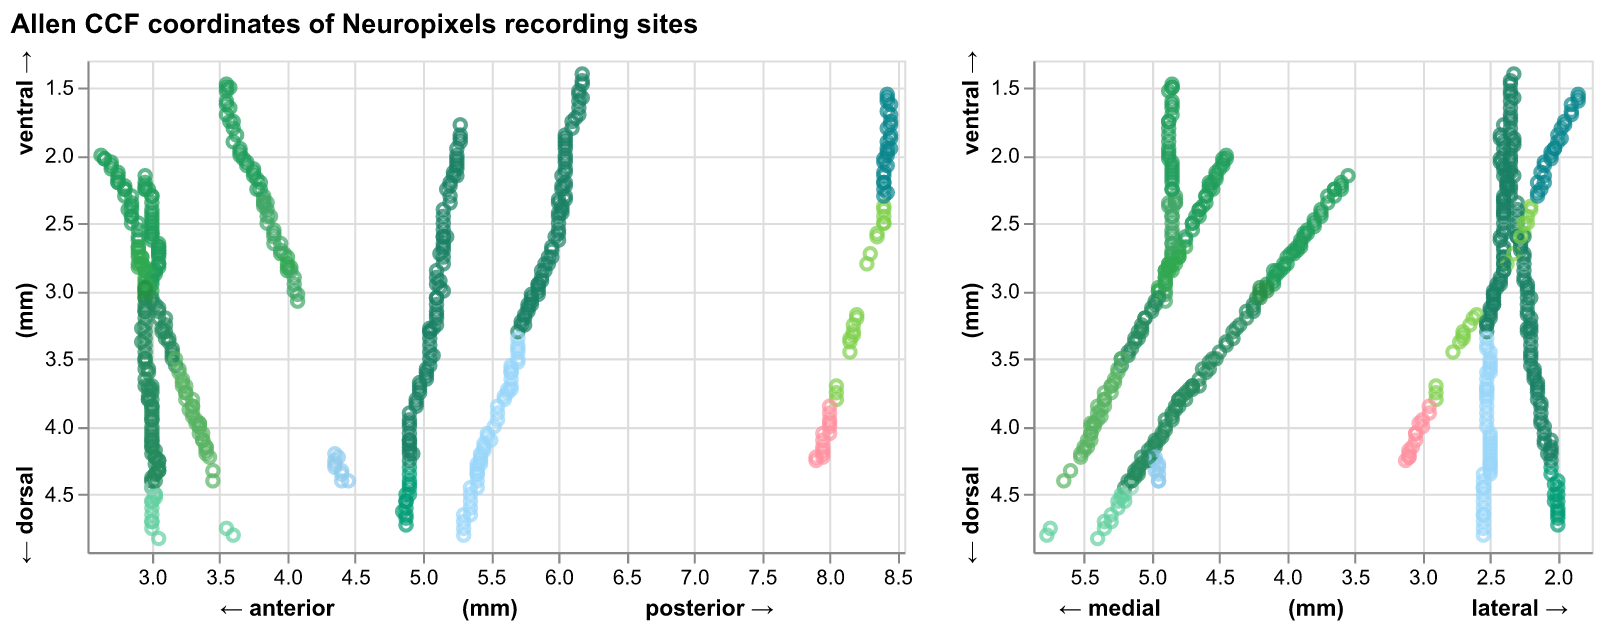

In [21]:
# CCF coordinates are stored in microns; convert to millimeters for plotting.
ccf_coordinate_cols = ["ccf_ap", "ccf_ml", "ccf_dv"]
tooltip_cols = ["structure", "unit_id", "is_qc_pass", "electrode_group_name"]

unit_ccf = (
    units.select([*tooltip_cols, *ccf_coordinate_cols, "decoder_label"])
    .filter(pl.col("decoder_label") != "noise")
    .unique(ccf_coordinate_cols)
    .with_columns(pl.col(ccf_coordinate_cols) / 1000)
)

ccf_colors = (
    pl.read_csv("https://raw.githubusercontent.com/cortex-lab/allenCCF/refs/heads/master/structure_tree_safe_2017.csv")
    .select("acronym", "color_hex_triplet")
    .unique("acronym")
)

color_map = (
    unit_ccf.select("structure")
    .unique()
    .join(ccf_colors, left_on="structure", right_on="acronym", how="left")
    .with_columns(("#" + pl.col("color_hex_triplet").fill_null("999999")).alias("color"))
    .sort("structure")
)


def padded_domain(values, padding=0.1, min_span=None):
    low = float(values.min()) - padding
    high = float(values.max()) + padding
    if min_span is not None and high - low < min_span:
        center = (low + high) / 2
        low = center - min_span / 2
        high = center + min_span / 2
    return [low, high]


def domain_pixels(domain):
    return max(1, round((domain[1] - domain[0]) * 65))


ccf_ap_domain = padded_domain(unit_ccf["ccf_ap"], min_span=2.0)
ccf_ml_domain = padded_domain(unit_ccf["ccf_ml"], min_span=2.0)
ccf_dv_domain = padded_domain(unit_ccf["ccf_dv"])
axis_gap = " " * 20

base = (
    alt.Chart(unit_ccf)
    .mark_point()
    .encode(
        tooltip=tooltip_cols,
        color=alt.Color(
            "structure",
            scale=alt.Scale(
                domain=color_map["structure"].to_list(),
                range=color_map["color"].to_list(),
            ),
            legend=None,
        ),
    )
)

ap_projection = base.encode(
    x=alt.X("ccf_ap", axis=alt.Axis(title=f"← anterior{axis_gap}(mm){axis_gap}posterior →"), scale=alt.Scale(domain=ccf_ap_domain, nice=False)),
    y=alt.Y("ccf_dv", axis=alt.Axis(title=f"← dorsal{axis_gap}(mm){axis_gap}ventral →"), scale=alt.Scale(domain=ccf_dv_domain, nice=False, reverse=True)),
).properties(width=domain_pixels(ccf_ap_domain), height=domain_pixels(ccf_dv_domain))

ml_projection = base.encode(
    x=alt.X("ccf_ml", axis=alt.Axis(title=f"← medial{axis_gap}(mm){axis_gap}lateral →"), scale=alt.Scale(domain=ccf_ml_domain, nice=False, reverse=True)),
    y=alt.Y("ccf_dv", axis=alt.Axis(title=f"← dorsal{axis_gap}(mm){axis_gap}ventral →"), scale=alt.Scale(domain=ccf_dv_domain, nice=False, reverse=True)),
).properties(width=domain_pixels(ccf_ml_domain), height=domain_pixels(ccf_dv_domain))

(ap_projection | ml_projection).properties(title="Allen CCF coordinates of Neuropixels recording sites")


## Single-unit exploration


### Metadata for a single unit

In [22]:
UNIT_ID = "742903_2024-10-22_E-775"

units.filter(pl.col("unit_id") == UNIT_ID).select(
    "structure",
    "location",
    "electrode_group_name",
    "is_qc_pass",
    "activity_drift",
)


structure,location,electrode_group_name,is_qc_pass,activity_drift
str,str,str,bool,f64
"""ORBl""","""ORBl6a""","""probeE""",true,0.096713


`is_qc_pass` allows quick filtering for units whose activity is stable over the task, and that do not appear to be noise.

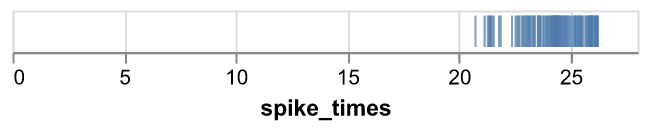

In [23]:
spike_times_df = (
    lazynwb.scan_nwb(selected_path, "/units")
    .filter(pl.col("unit_id") == UNIT_ID)
    .select("unit_id", "spike_times")
    .collect()
)
spike_times = spike_times_df["spike_times"][0].to_numpy()
truncated_spike_times = pl.DataFrame({"spike_times": spike_times[:100]})

alt.Chart(data=truncated_spike_times).mark_tick().encode(x="spike_times")


In [24]:
(
    lazynwb.scan_nwb(selected_path, "/units")
    .filter(pl.col("unit_id") == UNIT_ID)
    .select("obs_intervals")
    .collect()
)


obs_intervals
"list[array[f64, 2]]"
"[[20.251328, 7742.741729]]"


### Stimulus-aligned response (PSTH)

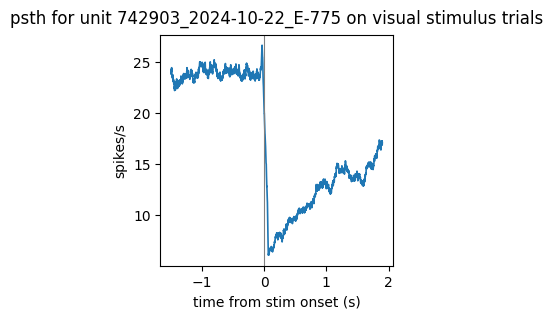

In [25]:
# time window around stimulus onset (seconds)
xmin = -1.5
xmax = 2.0
bin_size = 0.001  # 1 ms bins
smooth_ms = 100    # boxcar kernel width (ms)
smooth_bins = int(smooth_ms / (bin_size * 1000))

vis_trials = trials.filter(pl.col("is_vis_stim") & pl.col("stim_start_time").is_finite())

# count spikes in each bin, summed across all trials
bins = np.arange(xmin, xmax + bin_size, bin_size)
counts = np.zeros(len(bins) - 1)
for stim_start in vis_trials["stim_start_time"]:
    counts += np.histogram(spike_times - stim_start, bins=bins)[0]

# average across trials, then smooth and convert to Hz
psth_hz = np.convolve(
    counts / len(vis_trials),
    np.ones(smooth_bins) / (smooth_bins * bin_size),
    mode="valid",
)
t = xmin + np.arange(len(psth_hz)) * bin_size

plt.plot(t, psth_hz, lw=1.2)
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("time from stim onset (s)")
plt.ylabel("spikes/s")
plt.gcf().set_size_inches(3, 3)
plt.title(f"psth for unit {UNIT_ID} on visual stimulus trials", pad=8)
plt.show()


## Activity by stimulus and block

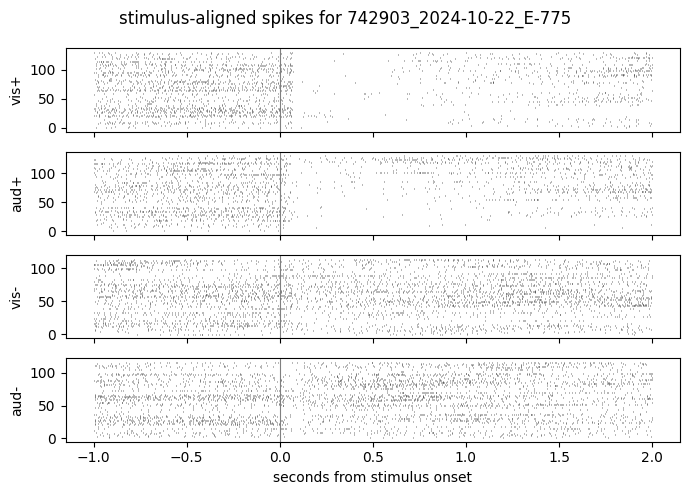

In [26]:
unit_id = UNIT_ID

# Or use a custom units filter and get a random unit:
random_unit_id = units.filter(
    (pl.col("is_qc_pass"))
    & (pl.col("structure") == "MOs")
    & (pl.col("firing_rate") > 5)
).sample(1)["unit_id"][0]
# unit_id = random_unit_id

unit_spikes = (
    lazynwb.scan_nwb(selected_path, "/units")
    .filter(pl.col("unit_id") == unit_id)
    .select("spike_times")
    .collect()["spike_times"][0]
    .to_numpy()
)

stim_names = ["vis+", "aud+", "vis-", "aud-"]
plot_trials = trials.filter(pl.col("stim_name").is_in(stim_names)).sort("block_index", "trial_index_in_block")

fig, axes = plt.subplots(len(stim_names), 1, figsize=(7, 5), sharex=True)
for ax, stim_name in zip(axes, stim_names):
    stim_trials = plot_trials.filter(pl.col("stim_name") == stim_name)
    for row_index, trial in enumerate(stim_trials.iter_rows(named=True)):
        start = trial["stim_start_time"] - 1
        stop = trial["stim_start_time"] + 2
        trial_spikes = unit_spikes[(unit_spikes >= start) & (unit_spikes <= stop)] - trial["stim_start_time"]
        ax.vlines(trial_spikes, row_index - 0.4, row_index + 0.4, color="black", linewidth=0.4)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_ylabel(stim_name)

axes[-1].set_xlabel("seconds from stimulus onset")
fig.suptitle(f"stimulus-aligned spikes for {unit_id}", y=0.98)
plt.tight_layout()
plt.show()



---
# Behavioral data

## Accessing timeseries containers


In [27]:
running_speed = lazynwb.get_timeseries(
    selected_path,
    "/processing/behavior/running_speed",
    exact_path=True,
)
display(running_speed.timestamps, running_speed.data)


<Array <FsspecStore(S3FileSystem, aind-open-data/ecephys_742903_2024-10-22_10-58-35_nwb_2026-05-18_22-02-14/742903_2024-10-22.nwb.zarr)>/processing/behavior/running_speed/timestamps shape=(450128,) dtype=float64>

In [28]:
sampling_rate_hz = 1 / np.median(np.diff(running_speed.timestamps[:1000]))
sampling_rate_hz 

np.float64(59.95203836930126)

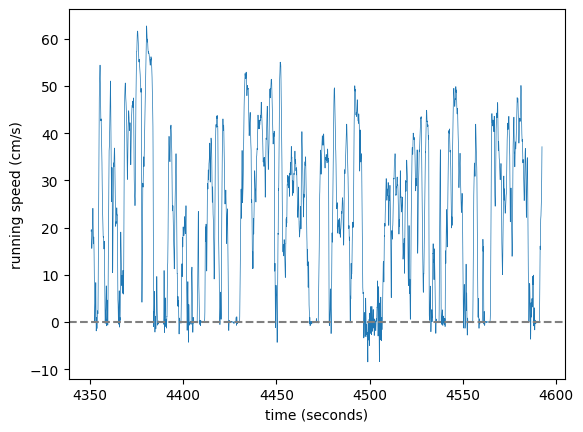

In [29]:
n_samples_to_plot = int(sampling_rate_hz * 60 * 4)
start_sample = int(sampling_rate_hz * 60 * 70)  # at 70 min the task is ongoing

t = running_speed.timestamps[start_sample:start_sample + n_samples_to_plot]
y = running_speed.data[start_sample:start_sample + n_samples_to_plot]

plt.plot(t, y, lw=0.5)
plt.axhline(0, color="gray", linestyle="dashed")
plt.xlabel(f"time ({running_speed.timestamps_unit})")
plt.ylabel(f"running speed ({running_speed.unit})")
plt.show()


## Running speed by outcome and block

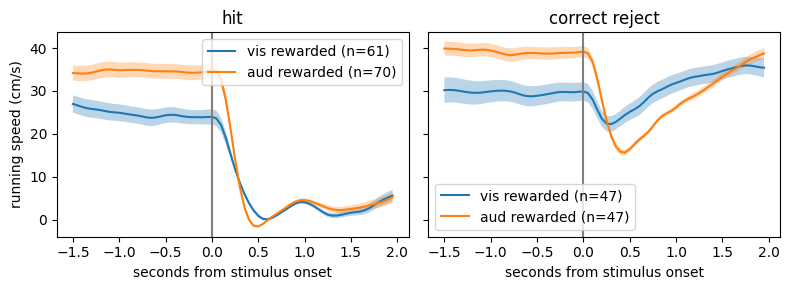

In [30]:
running_time_grid = np.arange(-1.5, 2, 0.05)

# filter trials to hits and correct rejects, excluding instructions and catch
running_trials = (
    trials.filter(
        (pl.col("is_vis_target") | pl.col("is_aud_target"))
        & (pl.col("is_hit") | pl.col("is_correct_reject"))
    )
    .with_columns(
        pl.when(pl.col("is_hit"))
        .then(pl.lit("hit"))
        .otherwise(pl.lit("correct reject"))
        .alias("outcome")
    )
)

# load running speed as numpy arrays
rs_times = np.array(running_speed.timestamps)
rs_data = np.array(running_speed.data)

# align running speed to each trial's stimulus onset
aligned_rows = []
for trial in running_trials.iter_rows(named=True):
    sample_times = trial["stim_start_time"] + running_time_grid
    if sample_times[0] < rs_times[0] or sample_times[-1] > rs_times[-1]:
        continue
    aligned_rows.append({
        "rewarded_modality": trial["rewarded_modality"],
        "outcome": trial["outcome"],
        "running_speed": np.interp(sample_times, rs_times, rs_data),
    })

fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True, sharey=True)
for col_idx, outcome in enumerate(["hit", "correct reject"]):
    ax = axes[col_idx]
    for modality in ["vis", "aud"]:
        traces_for_group = [
            row["running_speed"] for row in aligned_rows
            if row["outcome"] == outcome and row["rewarded_modality"] == modality
        ]
        if not traces_for_group:
            continue
        traces = np.vstack(traces_for_group)
        mean = traces.mean(axis=0)
        sem = traces.std(axis=0, ddof=1) / np.sqrt(len(traces))
        ax.plot(running_time_grid, mean, label=f"{modality} rewarded (n={len(traces)})")
        ax.fill_between(running_time_grid, mean - sem, mean + sem, alpha=0.3)
    ax.axvline(0, color="gray")
    ax.set_title(outcome)
    ax.set_xlabel("seconds from stimulus onset")
    if col_idx == 0:
        ax.set_ylabel(f"running speed ({running_speed.unit})")
    ax.legend()
plt.tight_layout()
plt.show()


## Facial features from `lightning pose (lp)` 

In [31]:
lazynwb.get_table_schema(
    selected_path,
    "/processing/behavior/lp_side_camera",
    exclude_internal_columns=True,
)


Schema([('ear_base_l_likelihood', Float64),
        ('ear_base_l_pca_error', Float64),
        ('ear_base_l_temporal_norm', Float64),
        ('ear_base_l_x', Float64),
        ('ear_base_l_y', Float64),
        ('ear_tip_l_likelihood', Float64),
        ('ear_tip_l_pca_error', Float64),
        ('ear_tip_l_temporal_norm', Float64),
        ('ear_tip_l_x', Float64),
        ('ear_tip_l_y', Float64),
        ('eye_bottom_l_likelihood', Float64),
        ('eye_bottom_l_pca_error', Float64),
        ('eye_bottom_l_temporal_norm', Float64),
        ('eye_bottom_l_x', Float64),
        ('eye_bottom_l_y', Float64),
        ('eye_top_l_likelihood', Float64),
        ('eye_top_l_pca_error', Float64),
        ('eye_top_l_temporal_norm', Float64),
        ('eye_top_l_x', Float64),
        ('eye_top_l_y', Float64),
        ('id', Int64),
        ('jaw_likelihood', Float64),
        ('jaw_pca_error', Float64),
        ('jaw_temporal_norm', Float64),
        ('jaw_x', Float64),
        ('jaw_y', Fl

![Screenshot 2026-05-14 at 2.37.37 PM.png](<attachment:Screenshot 2026-05-14 at 2.37.37 PM.png>)
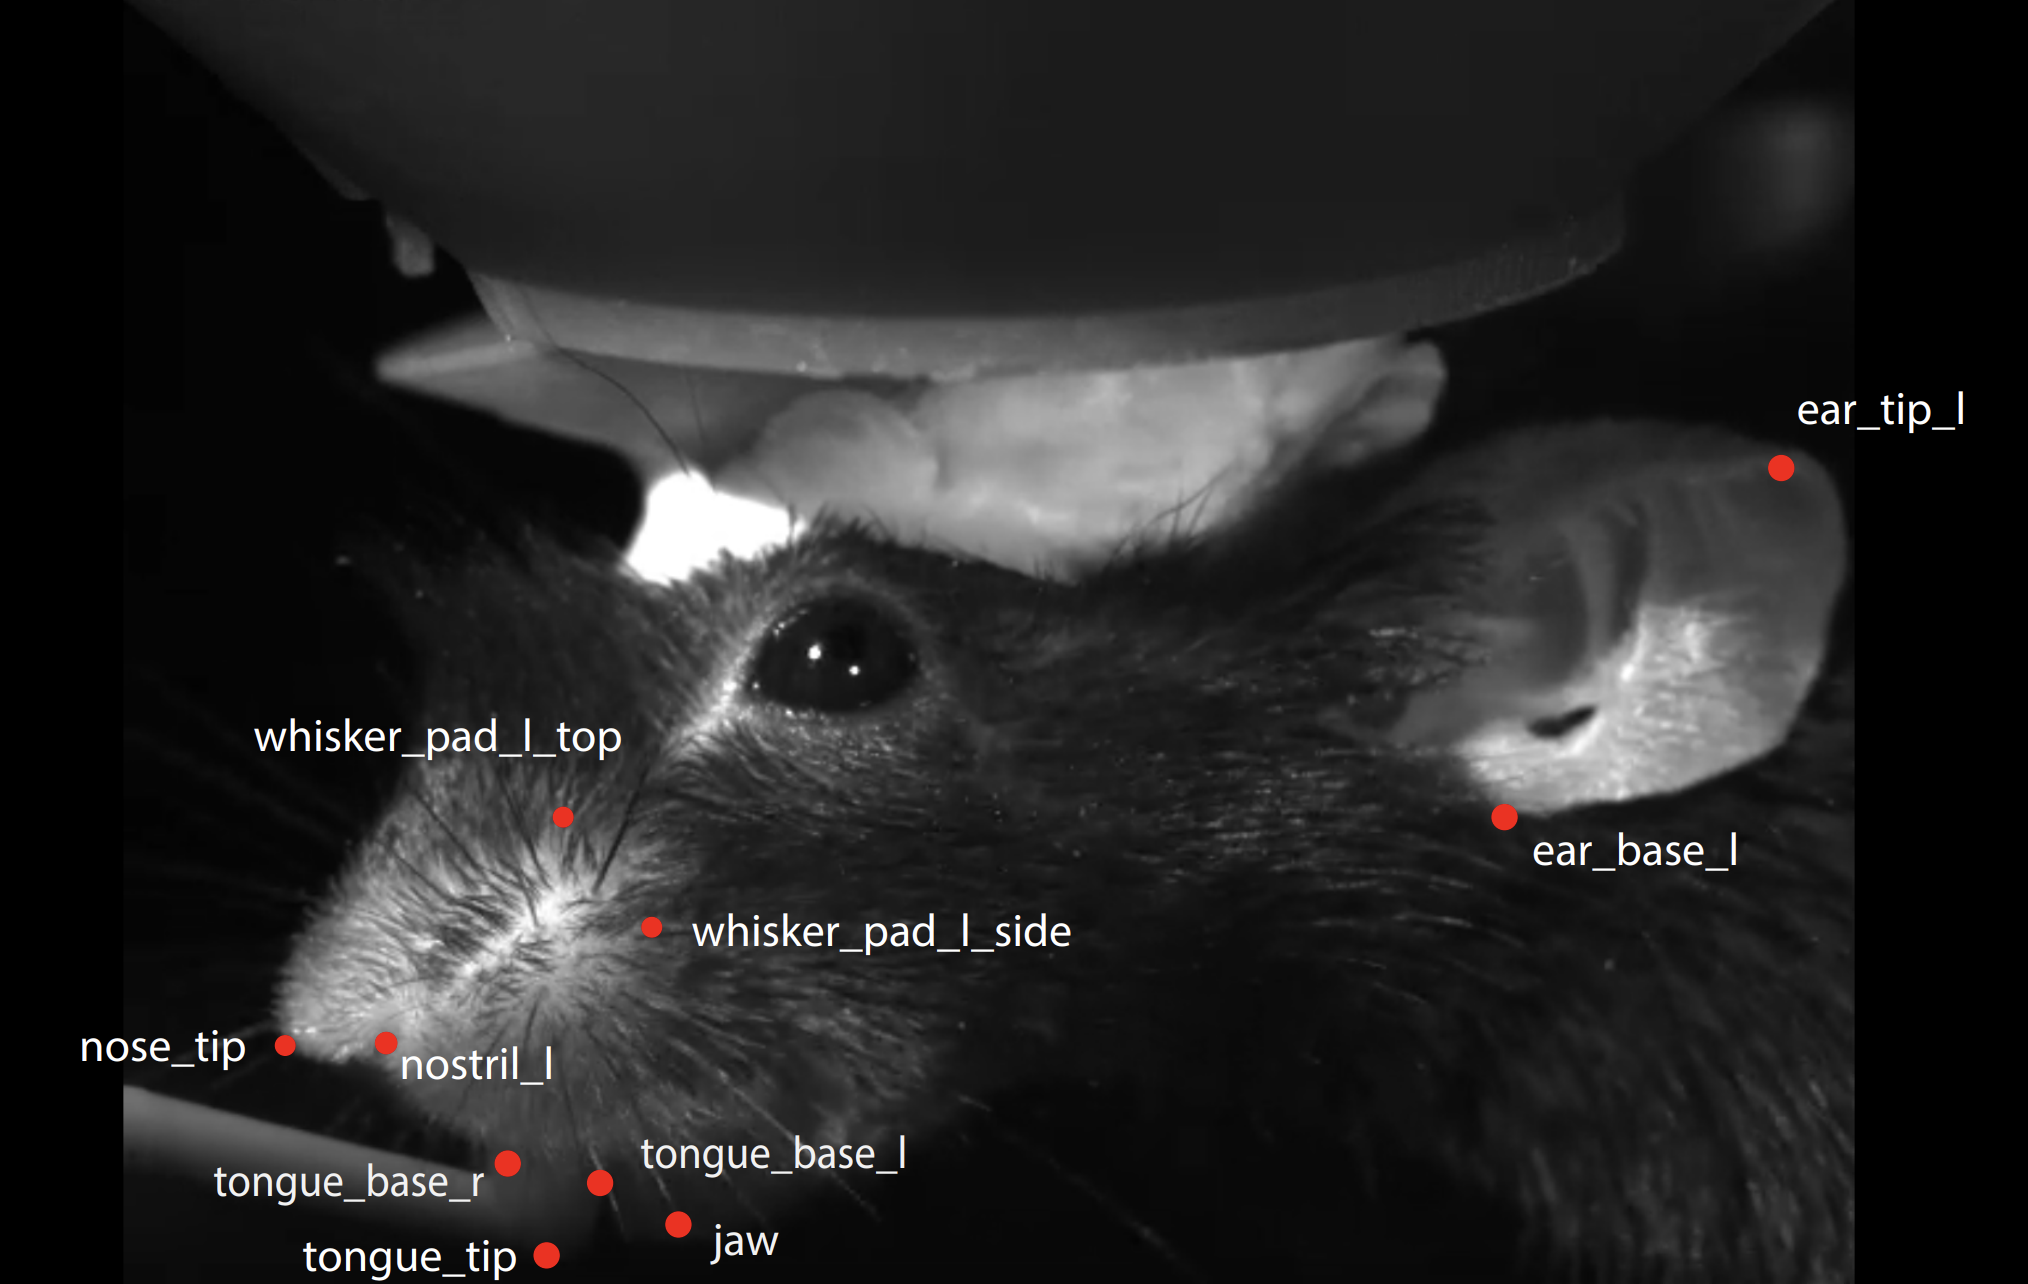

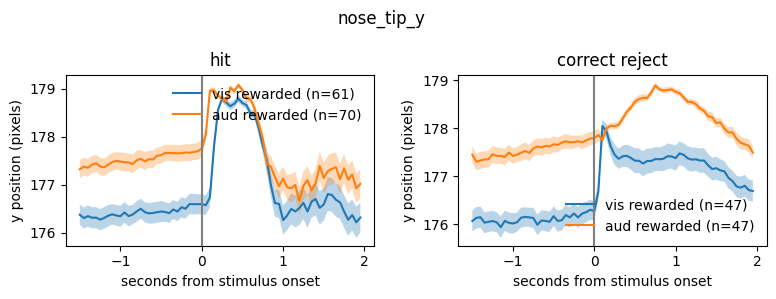

In [33]:
keypoint = "nose_tip_y"

# filter trials (same criteria as running speed)
pose_trials = (
    trials.filter(
        (pl.col("is_vis_target") | pl.col("is_aud_target"))
        & (pl.col("is_hit") | pl.col("is_correct_reject"))
    )
    .with_columns(
        pl.when(pl.col("is_hit"))
        .then(pl.lit("hit"))
        .otherwise(pl.lit("correct reject"))
        .alias("outcome")
    )
)

# extract keypoint data
lp_df = (
    lazynwb.scan_nwb(selected_path, "/processing/behavior/lp_side_camera")
    .select("timestamps", keypoint)
    .filter(pl.col("timestamps").is_finite(), pl.col(keypoint).is_finite())
    .collect()
)

pose_times = lp_df["timestamps"].to_numpy()
pose_values = lp_df[keypoint].to_numpy()

# align keypoint to each trial's stimulus onset
xmin = -1.5
pose_time_grid = np.arange(xmin, 2.0, 0.05)
aligned_rows = []
for trial in pose_trials.iter_rows(named=True):
    sample_times = trial["stim_start_time"] + pose_time_grid
    if sample_times[0] < pose_times[0] or sample_times[-1] > pose_times[-1]:
        continue
    values = np.interp(sample_times, pose_times, pose_values)
    aligned_rows.append({
        "rewarded_modality": trial["rewarded_modality"],
        "outcome": trial["outcome"],
        "values": values,
    })

# plot nose tip by outcome
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True)
for col_idx, outcome in enumerate(["hit", "correct reject"]):
    ax = axes[col_idx]
    for modality in ["vis", "aud"]:
        traces_for_group = [
            row["values"] for row in aligned_rows
            if row["outcome"] == outcome and row["rewarded_modality"] == modality
        ]
        if not traces_for_group:
            continue
        traces = np.vstack(traces_for_group)
        mean = traces.mean(axis=0)
        sem = traces.std(axis=0, ddof=1) / np.sqrt(len(traces))
        ax.plot(pose_time_grid, mean, label=f"{modality} rewarded (n={len(traces)})")
        ax.fill_between(pose_time_grid, mean - sem, mean + sem, alpha=0.3)
    ax.axvline(0, color="gray")
    ax.set_title(outcome)
    ax.set_xlabel("seconds from stimulus onset")
    ax.set_ylabel("y position (pixels)")
    ax.legend(frameon=False)

plt.suptitle(keypoint)
plt.tight_layout()
plt.show()
